### Проведення серій дослідження впливу розміру графів на прискорення та впливу кількості потоків для паралельного Фільтр-Крускала

In [1]:
# 1. Дані й параметри досліду
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESULTS = "C:/Users/admin/source/repos/Kruskal/results/"
CSV = RESULTS + "fk_par_threads_ab.csv"
MIN_EDGES = 1_000_000                 # серія 2: лише великі графи
P_SERIES1 = 8                         # серія 1: кількість потоків для порівняння за обсягом даних
VARIANTS = {8192: "A", 262144: "B"}   # поріг базового випадку -> варіант fk-par

PARAMS = ["threads", "threshold", "partition_block", "filter_block", "par_cutoff", "psort_cutoff"]

def experiment_params(df):
    rows = {}
    for alg, d in df.groupby("algorithm", sort=False):
        row = {}
        for c in PARAMS:
            vals = sorted(d[c].dropna().unique())
            row[c] = ", ".join(str(int(v)) for v in vals) if vals else "-"
        repeats = d.groupby(["graph"] + PARAMS, dropna=False)["repeat"].nunique()
        row["повторів"] = f"{repeats.min()}–{repeats.max()}" if repeats.min() != repeats.max() else str(repeats.min())
        rows[alg] = row
    graphs = df["graph"].unique()
    print(f"Графи ({len(graphs)}): {', '.join(graphs)}")
    return pd.DataFrame(rows).T

df = pd.read_csv(CSV)
order = list(df["graph"].unique())
info = df.groupby("graph", sort=False)[["family", "V", "E"]].first()
big = [g for g in order if info.loc[g, "E"] >= MIN_EDGES]

display(experiment_params(df))

Графи (19): B1, B2, B3, B4, B5, B6, B7, B8, B9, B10, B11, G1, C1, C2, C3, C4, C5, C6, C7


,threads,threshold,partition_block,filter_block,par_cutoff,psort_cutoff,повторів
fk,1,"8192, 262144, 1048576",-,-,-,-,6–25
fk-par,"1, 2, 4, 6, 8, 12, 16","8192, 262144, 1048576",8192,2048,65536,32768,6–25


In [3]:
# 2. Еталон: найкращий послідовний FK на кожному графі
fk = df[df["algorithm"] == "fk"].groupby(["graph", "threshold"], as_index=False)["total_ms"].mean()
best_fk = fk.loc[fk.groupby("graph")["total_ms"].idxmin()].set_index("graph").reindex(order)
seq = best_fk["total_ms"]

print("Послідовний FK, середній час, мс (останній стовпець - найкращий поріг):")
fk_table = fk.pivot(index="graph", columns="threshold", values="total_ms").reindex(order)
fk_table["найкращий T"] = best_fk["threshold"]
display(fk_table.round(2))

Послідовний FK, середній час, мс (останній стовпець - найкращий поріг):


threshold,8192,262144,1048576,найкращий T
graph,,,,
B1,0.94,1.07,1.07,8192
B2,1.01,1.98,1.98,8192
B3,1.35,4.05,4.10,8192
B4,2.29,8.34,8.35,8192
B5,3.42,17.01,16.90,8192
B6,6.61,19.86,34.90,8192
B7,12.00,23.76,69.81,8192
B8,23.96,29.85,76.60,8192
B9,44.32,49.54,83.17,8192


In [4]:
# 3. fk-par: середній час, прискорення й ефективність для варіантів A і B
par = df[(df["algorithm"] == "fk-par") & (df["threshold"].isin(VARIANTS))]
par = par.groupby(["graph", "threshold", "threads"], as_index=False)["total_ms"].mean()
par["variant"] = par["threshold"].map(VARIANTS)
par["speedup"] = par["graph"].map(seq) / par["total_ms"]    # S_p відносно найкращого послідовного FK
par["efficiency"] = par["speedup"] / par["threads"]         # E_p = S_p / p
threads = sorted(par["threads"].unique())


def by_threads(values, variant, graphs):
    d = par[par["variant"] == variant]
    return d.pivot(index="graph", columns="threads", values=values).reindex(graphs)

In [16]:
# 4. Серія 2. Вплив кількості потоків (великі графи)
for v in VARIANTS.values():
    print(f"=== Варіант {v}: прискорення S_p відносно найкращого послідовного FK")
    display(by_threads("speedup", v, big).round(2))
for v in VARIANTS.values():
    print(f"=== Варіант {v}: ефективність E_p = S_p / p")
    display(by_threads("efficiency", v, big).round(2))

best_p = (par[par["graph"].isin(big)]
            .loc[lambda d: d.groupby(["graph", "variant"])["speedup"].idxmax()]
            .pivot(index="graph", columns="variant", values=["threads", "speedup"])
            .reindex(big))
print("Найбільше прискорення на кожному графі (p, при якому досягнуто, і саме прискорення):")
display(best_p.round(2).astype({("threads", "A"): int, ("threads", "B"): int}))

=== Варіант A: прискорення S_p відносно найкращого послідовного FK


threads,1,2,4,6,8,12,16
graph,,,,,,,
B7,0.58,0.91,1.21,1.30,1.35,1.31,1.30
B8,0.57,0.91,1.21,1.32,1.36,1.37,1.36
B9,0.56,0.85,1.21,1.27,1.31,1.28,1.32
B10,0.53,0.87,1.17,1.25,1.26,1.26,1.26
B11,0.52,0.84,1.15,1.23,1.25,1.24,1.24
G1,0.68,0.94,1.14,1.21,1.22,1.18,1.19
C4,0.70,0.92,1.13,1.20,1.20,1.13,1.12
C5,0.66,0.91,1.17,1.22,1.20,1.19,1.17
C6,0.68,1.02,1.32,1.42,1.42,1.37,1.38


=== Варіант B: прискорення S_p відносно найкращого послідовного FK


threads,1,2,4,6,8,12,16
graph,,,,,,,
B7,0.38,0.62,0.88,1.02,1.05,1.09,1.09
B8,0.45,0.75,1.05,1.17,1.20,1.22,1.22
B9,0.51,0.81,1.14,1.22,1.27,1.24,1.28
B10,0.51,0.84,1.13,1.21,1.24,1.23,1.23
B11,0.52,0.85,1.14,1.23,1.23,1.24,1.24
G1,0.79,1.19,1.53,1.66,1.68,1.65,1.66
C4,0.71,1.10,1.46,1.59,1.63,1.59,1.59
C5,0.69,1.10,1.47,1.59,1.60,1.55,1.56
C6,0.74,1.17,1.57,1.74,1.71,1.71,1.70


=== Варіант A: ефективність E_p = S_p / p


threads,1,2,4,6,8,12,16
graph,,,,,,,
B7,0.58,0.46,0.30,0.22,0.17,0.11,0.08
B8,0.57,0.45,0.30,0.22,0.17,0.11,0.09
B9,0.56,0.42,0.30,0.21,0.16,0.11,0.08
B10,0.53,0.43,0.29,0.21,0.16,0.11,0.08
B11,0.52,0.42,0.29,0.20,0.16,0.10,0.08
G1,0.68,0.47,0.29,0.20,0.15,0.10,0.07
C4,0.70,0.46,0.28,0.20,0.15,0.09,0.07
C5,0.66,0.46,0.29,0.20,0.15,0.10,0.07
C6,0.68,0.51,0.33,0.24,0.18,0.11,0.09


=== Варіант B: ефективність E_p = S_p / p


threads,1,2,4,6,8,12,16
graph,,,,,,,
B7,0.38,0.31,0.22,0.17,0.13,0.09,0.07
B8,0.45,0.38,0.26,0.20,0.15,0.10,0.08
B9,0.51,0.40,0.28,0.20,0.16,0.10,0.08
B10,0.51,0.42,0.28,0.20,0.16,0.10,0.08
B11,0.52,0.43,0.29,0.21,0.15,0.10,0.08
G1,0.79,0.59,0.38,0.28,0.21,0.14,0.10
C4,0.71,0.55,0.36,0.27,0.20,0.13,0.10
C5,0.69,0.55,0.37,0.26,0.20,0.13,0.10
C6,0.74,0.58,0.39,0.29,0.21,0.14,0.11


Найбільше прискорення на кожному графі (p, при якому досягнуто, і саме прискорення):


threads     speedup      
variant       A   B       A     B
graph                            
B7            8  16    1.35  1.09
B8           12  12    1.37  1.22
B9           16  16    1.32  1.28
B10          12   8    1.26  1.24
B11           8  12    1.25  1.24
G1            8   8    1.22  1.68
C4            8   8    1.20  1.63
C5            6   8    1.22  1.60
C6            6   6    1.42  1.74
C7           12   8    1.47  1.75

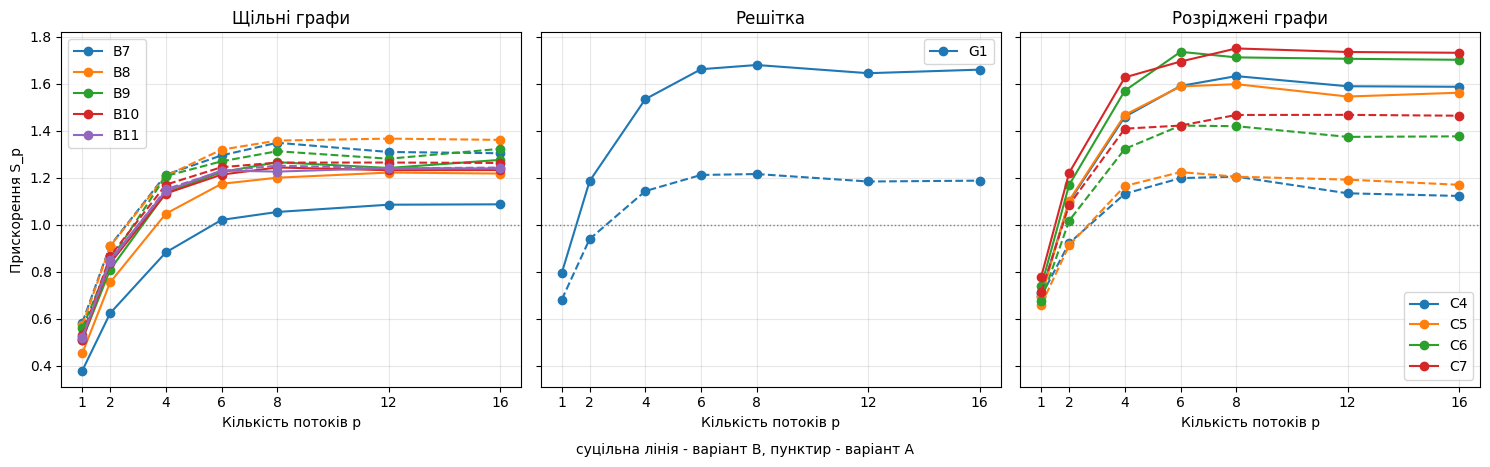

In [7]:
# 5. Серія 2. Графік прискорення від кількості потоків: пунктир = A, суцільна - B
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
families = [("dense", "Щільні графи"), ("grid", "Решітка"), ("sparse", "Розріджені графи")]
for ax, (family, title) in zip(axes, families):
    for i, g in enumerate(gr for gr in big if info.loc[gr, "family"] == family):
        for v, ls in [("A", "--"), ("B", "-")]:
            d = par[(par["graph"] == g) & (par["variant"] == v)].sort_values("threads")
            ax.plot(d["threads"], d["speedup"], ls=ls, marker="o", color=f"C{i}",
                    label=g if v == "B" else None)
    ax.axhline(1, color="gray", lw=1, ls=":")
    ax.set_xticks(threads)
    ax.set_xlabel("Кількість потоків p")
    ax.set_title(title)
    ax.grid(alpha=0.3)
    if ax.get_legend_handles_labels()[0]:
        ax.legend(fontsize=10)
axes[0].set_ylabel("Прискорення S_p")
fig.text(0.5, -0.02, "суцільна лінія - варіант B, пунктир - варіант A", ha="center", fontsize=10)
fig.tight_layout()
fig.savefig(RESULTS + "fk_par_ab_threads.png", dpi=200, bbox_inches="tight")
plt.show()

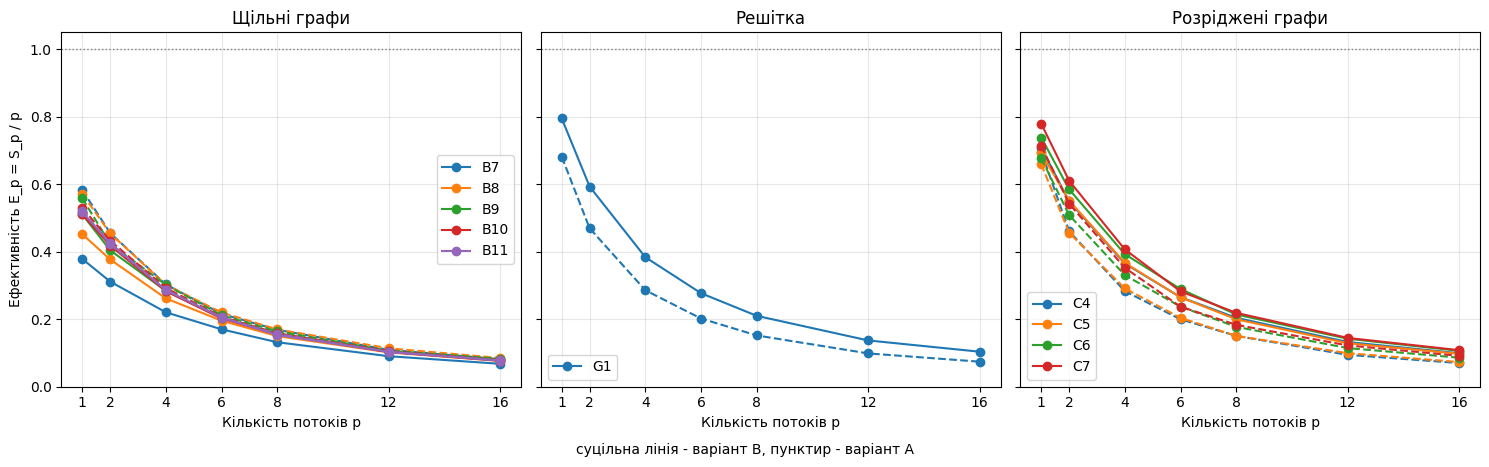

In [13]:
# 5б. Серія 2. Графік ефективності від кількості потоків: пунктир — A, суцільна — B
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
families = [("dense", "Щільні графи"), ("grid", "Решітка"), ("sparse", "Розріджені графи")]
for ax, (family, title) in zip(axes, families):
    for i, g in enumerate(gr for gr in big if info.loc[gr, "family"] == family):
        for v, ls in [("A", "--"), ("B", "-")]:
            d = par[(par["graph"] == g) & (par["variant"] == v)].sort_values("threads")
            ax.plot(d["threads"], d["efficiency"], ls=ls, marker="o", color=f"C{i}",
                    label=g if v == "B" else None)
    ax.axhline(1, color="gray", lw=1, ls=":")      # ідеальна ефективність
    ax.set_xticks(threads)
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("Кількість потоків p")
    ax.set_title(title)
    ax.grid(alpha=0.3)
    if ax.get_legend_handles_labels()[0]:
        ax.legend(fontsize=10)
axes[0].set_ylabel("Ефективність E_p = S_p / p")
fig.text(0.5, -0.02, "суцільна лінія - варіант B, пунктир - варіант A", ha="center", fontsize=10)
fig.tight_layout()
fig.savefig(RESULTS + "fk_par_ab_efficiency.png", dpi=200, bbox_inches="tight")
plt.show()

In [8]:
# 6. Серія 1. Вплив обсягу даних (усі графи, p = P_SERIES1)
at_p = par[par["threads"] == P_SERIES1]
tA = at_p[at_p["variant"] == "A"].set_index("graph")["total_ms"]
tB = at_p[at_p["variant"] == "B"].set_index("graph")["total_ms"]
series1 = pd.DataFrame({
    "V": info["V"],
    "E": info["E"],
    "FK: найкращий T": best_fk["threshold"],
    "FK, мс": seq,
    "A, мс": tA,
    "S_A": seq / tA,
    "B, мс": tB,
    "S_B": seq / tB,
}).reindex(order)
print(f"Серія 1: прискорення при p = {P_SERIES1} відносно найкращого послідовного FK")
display(series1.round(2))

Серія 1: прискорення при p = 8 відносно найкращого послідовного FK


,V,E,FK: найкращий T,"FK, мс","A, мс",S_A,"B, мс",S_B
graph,,,,,,,,
B1,8000,16000,8192,0.94,0.91,1.04,1.04,0.91
B2,8000,32000,8192,1.01,0.99,1.01,1.95,0.51
B3,8000,64000,8192,1.35,1.36,0.99,1.72,0.78
B4,8000,128000,8192,2.29,2.27,1.01,2.96,0.77
B5,8000,256000,8192,3.42,3.29,1.04,5.30,0.64
B6,8000,512000,8192,6.61,5.10,1.30,8.02,0.82
B7,8000,1024000,8192,12.00,8.90,1.35,11.38,1.05
B8,8000,2048000,8192,23.96,17.64,1.36,19.96,1.20
B9,8000,4096000,8192,44.32,33.75,1.31,35.00,1.27


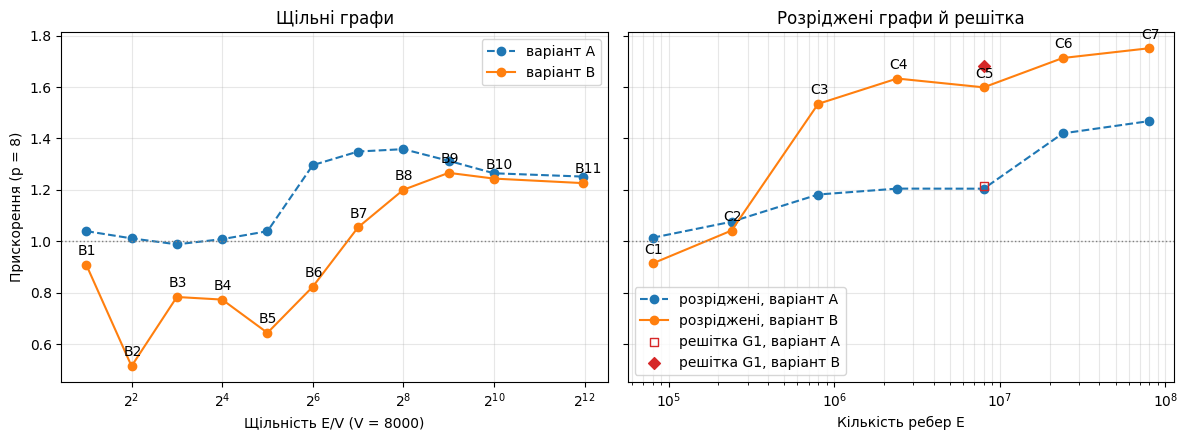

In [10]:
# 7. Серія 1. Графік прискорення від обсягу даних: пунктир - A, суцільна - B
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

dense = [g for g in order if info.loc[g, "family"] == "dense"]
x = info.loc[dense, "E"] / info.loc[dense, "V"]
for v, ls in [("A", "--"), ("B", "-")]:
    axes[0].plot(x, series1.loc[dense, f"S_{v}"], ls=ls, marker="o", label=f"варіант {v}")
for xi, yi, g in zip(x, series1.loc[dense, "S_B"], dense):
    axes[0].annotate(g, (xi, yi), textcoords="offset points", xytext=(-6, 7), fontsize=10)
axes[0].set_xscale("log", base=2)
axes[0].set_xlabel("Щільність E/V (V = 8000)")
axes[0].set_title("Щільні графи")

sparse = [g for g in order if info.loc[g, "family"] == "sparse"]
grid = [g for g in order if info.loc[g, "family"] == "grid"]
for v, ls in [("A", "--"), ("B", "-")]:
    axes[1].plot(info.loc[sparse, "E"], series1.loc[sparse, f"S_{v}"], ls=ls, marker="o",
                 label=f"розріджені, варіант {v}")
for v, marker in [("A", "s"), ("B", "D")]:
    axes[1].scatter(info.loc[grid, "E"], series1.loc[grid, f"S_{v}"], marker=marker, zorder=3,
                    color="tab:red", facecolors="none" if v == "A" else "tab:red",
                    label=f"решітка G1, варіант {v}")
for xi, yi, g in zip(info.loc[sparse, "E"], series1.loc[sparse, "S_B"], sparse):
    axes[1].annotate(g, (xi, yi), textcoords="offset points", xytext=(-6, 7), fontsize=10)
axes[1].set_xscale("log")
axes[1].set_xlabel("Кількість ребер E")
axes[1].set_title("Розріджені графи й решітка")

for ax in axes:
    ax.axhline(1, color="gray", lw=1, ls=":")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=10)
axes[0].set_ylabel(f"Прискорення (p = {P_SERIES1})")
fig.tight_layout()
fig.savefig(RESULTS + "fk_par_ab_size.png", dpi=200, bbox_inches="tight")
plt.show()

In [11]:
#8. Розкид між повторами
d = df[df["E"] >= MIN_EDGES]
noise = (d.groupby(["graph", "algorithm", "threshold", "threads"])["total_ms"]
           .agg(lambda x: x.std() / x.mean()).median() * 100)
print(f"Типовий розкид між повторами на великих графах: {noise:.1f}%")

Типовий розкид між повторами на великих графах: 1.1%


In [17]:
fk8 = (df[(df["algorithm"] == "fk") & (df["threshold"] == 8192)]
         .groupby("graph", sort=False)[["total_ms", "sorted_edges"]].mean())
sorted_table = pd.DataFrame({
    "V": info["V"],
    "E": info["E"],
    "Відсортовано ребер": fk8["sorted_edges"].round().astype(int),
    "Відсортовано, %": (100 * fk8["sorted_edges"] / info["E"]).round(2),
    "Час FK на ребро, нс": (fk8["total_ms"] * 1e6 / info["E"]).round(2),
}).reindex(order)
display(sorted_table)

,V,E,Відсортовано ребер,"Відсортовано, %","Час FK на ребро, нс"
graph,,,,,
B1,8000,16000,11449,71.56,58.91
B2,8000,32000,11442,35.76,31.43
B3,8000,64000,11337,17.71,21.03
B4,8000,128000,11788,9.21,17.88
B5,8000,256000,11641,4.55,13.35
B6,8000,512000,11305,2.21,12.90
B7,8000,1024000,11422,1.12,11.72
B8,8000,2048000,11149,0.54,11.70
B9,8000,4096000,11585,0.28,10.82
